### Testing different p values by changing data points 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress
from itertools import product

spring = pd.read_csv("../../data/ratios_VHF_spring.csv")
summer = pd.read_csv("../../data/ratios_VHF_summer.csv")

spring.columns = spring.columns.str.strip()
summer.columns = summer.columns.str.strip()

grain_size_columns = [
    "coarse_sand",
    "fine_sand",
    "silt",
    "clay"
]

results = []

In [5]:
for grain_size in grain_size_columns:

    # Keep valid observations from each season
    spring_valid = spring[
        ["probe", "VHF", grain_size]
    ].dropna()

    summer_valid = summer[
        ["probe", "VHF", grain_size]
    ].dropna()

    # Match observations by physical probe
    paired = spring_valid.merge(
        summer_valid,
        on="probe",
        suffixes=("_spring", "_summer")
    )

    if len(paired) != 5:
        raise ValueError(
            f"{grain_size}: expected 5 matched probes, "
            f"found {len(paired)}."
        )

    # Observed regression statistics
    spring_reg = linregress(
        paired["VHF_spring"],
        paired[f"{grain_size}_spring"]
    )

    summer_reg = linregress(
        paired["VHF_summer"],
        paired[f"{grain_size}_summer"]
    )

    observed_r2_diff = (
        spring_reg.rvalue**2 - summer_reg.rvalue**2
    )

    observed_slope_diff = (
        spring_reg.slope - summer_reg.slope
    )

    # Enumerate all possible paired seasonal swaps
    permutation_differences_r2 = []
    permutation_differences_slope = []

    for swaps in product([0, 1], repeat=len(paired)):

        spring_x = paired["VHF_spring"].to_numpy().copy()
        summer_x = paired["VHF_summer"].to_numpy().copy()

        spring_y = paired[f"{grain_size}_spring"].to_numpy().copy()
        summer_y = paired[f"{grain_size}_summer"].to_numpy().copy()

        swaps = np.array(swaps, dtype=bool)

        # Swap both VHF and sediment values within each probe
        spring_x[swaps], summer_x[swaps] = (
            summer_x[swaps].copy(),
            spring_x[swaps].copy()
        )

        spring_y[swaps], summer_y[swaps] = (
            summer_y[swaps].copy(),
            spring_y[swaps].copy()
        )

        reg_spring = linregress(spring_x, spring_y)
        reg_summer = linregress(summer_x, summer_y)

        permutation_differences_r2.append(
            reg_spring.rvalue**2 - reg_summer.rvalue**2
        )

        permutation_differences_slope.append(
            reg_spring.slope - reg_summer.slope
        )

    permutation_differences_r2 = np.array(
        permutation_differences_r2
    )

    permutation_differences_slope = np.array(
        permutation_differences_slope
    )

    # Two-sided exact permutation p-values
    p_r2 = np.mean(
        np.abs(permutation_differences_r2)
        >= abs(observed_r2_diff) - 1e-12
    )

    p_slope = np.mean(
        np.abs(permutation_differences_slope)
        >= abs(observed_slope_diff) - 1e-12
    )

    results.append({
        "grain_size": grain_size,
        "n_paired": len(paired),

        "spring_R2": spring_reg.rvalue**2,
        "summer_R2": summer_reg.rvalue**2,
        "delta_R2": observed_r2_diff,
        "permutation_p_R2": p_r2,

        "spring_slope": spring_reg.slope,
        "summer_slope": summer_reg.slope,
        "delta_slope": observed_slope_diff,
        "permutation_p_slope": p_slope,
    })

permutation_results = pd.DataFrame(results)

print(permutation_results.round(4))

#permutation_results.to_csv(
#    "paired_permutation_results.csv",
#    index=False
#)

    grain_size  n_paired  spring_R2  summer_R2  delta_R2  permutation_p_R2  \
0  coarse_sand         5     0.7443     0.2554    0.4889            0.4375   
1    fine_sand         5     0.7603     0.7439    0.0163            0.9375   
2         silt         5     0.6738     0.4041    0.2697            0.2500   
3         clay         5     0.6359     0.4233    0.2126            0.5000   

   spring_slope  summer_slope  delta_slope  permutation_p_slope  
0       -1.3110       -1.7674       0.4564               0.7500  
1       -1.9341       -1.9350       0.0009               1.0000  
2       -2.2666       -0.9626      -1.3040               0.1875  
3       -2.4986       -1.4322      -1.0664               0.4375  


### Original Linear Regressions

In [6]:
# Strip whitespace from headers so that the column names are consistent.
spring = spring.rename(columns=lambda column: column.strip())
summer = summer.rename(columns=lambda column: column.strip())

grain_size_columns = ["coarse_sand", "fine_sand", "silt", "clay"]
season_data = {"Spring": spring, "Summer": summer}

regression_rows = []
for season, data in season_data.items():
    for grain_size in grain_size_columns:
        valid = data[["VHF", grain_size]].dropna()
        if len(valid) < 3 or valid["VHF"].nunique() < 2:
            regression_rows.append({
                "season": season,
                "grain_size": grain_size,
                "n": len(valid),
                "slope": np.nan,
                "intercept": np.nan,
                "r_squared": np.nan,
                "p_value": np.nan,
            })
            continue

        regression = linregress(valid["VHF"], valid[grain_size])
        regression_rows.append({
            "season": season,
            "grain_size": grain_size,
            "n": len(valid),
            "slope": regression.slope,
            "intercept": regression.intercept,
            "r_squared": regression.rvalue ** 2,
            "p_value": regression.pvalue,
        })

regression_results = pd.DataFrame(regression_rows)
regression_results

,season,grain_size,n,slope,intercept,r_squared,p_value
0,Spring,coarse_sand,7,-1.779493,-0.148915,0.857034,0.002770
1,Spring,fine_sand,7,-1.974403,0.019691,0.543938,0.058508
2,Spring,silt,7,-2.301857,-0.048167,0.551370,0.055915
3,Spring,clay,7,-2.525609,-0.055886,0.550982,0.056048
4,Summer,coarse_sand,5,-1.767383,-0.427664,0.255416,0.385073
5,Summer,fine_sand,5,-1.935042,-0.052390,0.743931,0.059918
6,Summer,silt,5,-0.962597,0.133020,0.404051,0.249070
7,Summer,clay,5,-1.432234,0.014055,0.423289,0.234488


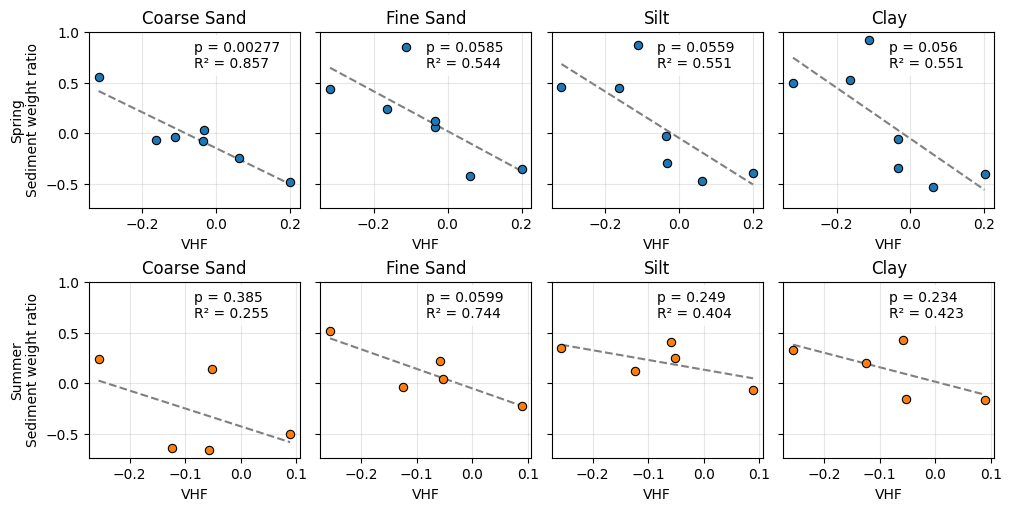

In [7]:
fig, axes = plt.subplots(
    nrows=len(season_data),
    ncols=len(grain_size_columns),
    figsize=(10, 5),
    sharey=True,
    constrained_layout=True,
)

colors = {"Spring": "tab:blue", "Summer": "tab:orange"}
for row, (season, data) in enumerate(season_data.items()):
    for column, grain_size in enumerate(grain_size_columns):
        ax = axes[row, column]
        valid = data[["VHF", grain_size]].dropna()
        result = regression_results[
            (regression_results["season"] == season)
            & (regression_results["grain_size"] == grain_size)
        ].iloc[0]

        ax.scatter(
            valid["VHF"],
            valid[grain_size],
            color=colors[season],
            edgecolor="black",
            linewidth=0.8,
            zorder=2,
        )
        if pd.notna(result["slope"]):
            x_line = np.linspace(valid["VHF"].min(), valid["VHF"].max(), 100)
            ax.plot(
                x_line,
                result["intercept"] + result["slope"] * x_line,
                color="grey",
                linewidth=1.5,
                zorder=1,
                linestyle="--",
            )
            annotation = f"p = {result['p_value']:.3g}\nR² = {result['r_squared']:.3f}"
        else:
            annotation = "Insufficient data"

        ax.text(
            0.5,
            0.95,
            annotation,
            transform=ax.transAxes,
            ha="left",
            va="top",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )
        ax.set_title(grain_size.replace("_", " ").title())
        ax.set_xlabel("VHF")
        ax.grid(alpha=0.3)
        if column == 0:
            ax.set_ylabel(f"{season}\nSediment weight ratio")

plt.show()